# 04 – Section 6.3.4: life calculation with the interaction equations of the codes

Recomputes Figures 6.27–6.44: IIW (modified Gough-Pollard, Eq. (2.34)), FKM (Eqs. (2.37)/(2.38)) and Eurocode 3 (Eq. (2.41)).
* Local stresses at the inner root notch (Tab. 6.1): $\sigma_\perp = \sigma_x$, $\sigma_\parallel = \sigma_y$, $\tau = \tau_{xy}$ (confirmed by the author).
* Bearable amplitudes from the normed axial and torsion S-N curves (Tab. 3.8) in local stresses, $k^* = 22$ (CA).
  For VA the Haibach slope $k' = 2k-2$ applies.
* δ = 90° and δ = 45° are nonproportional: CV = 0.5 for IIW and (2.38) for FKM (confirmed by the author). EC3 has no distinction.
* Variable amplitudes: damage-equivalent amplitude per component (2.25) from the standard rainflow count of the synthetic Gauss sequence (notebook 02), $D_{zul} = 0.5$.
  **Open point:** how the factor $1/D_{zul}$ in (2.25) and the iteration over N interact. The interpretation used here reduces to Palmgren-Miner (2.21) for uniaxial loading.
* The y-axis of the S-N plots (σ_GP,a, σ_FKM,a, σ_EC3,a) is the amplitude of the axial reference curve at $N_{rechn}$.
  This was verified with the torsion points of Fig. 6.27: 185 Nm → ≈ 357 MPa.

In [1]:
import os, sys
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mxpy.data import load_params, load_tests, include_in_statistics
from mxpy.codes import local_curves, life
from mxpy.woehler import L_eq
from mxpy.sequence import gauss_reversals
from mxpy.rainflow import rainflow_values
from mxpy import plotting

P = load_params()
df = load_tests()
RUNOUT_POLICY = 'exclude_DL'   # PRELIMINARY
tf = P['transfer_factors_tab_6_1']['inner']
r = P['Mt_over_F']
CODES = [('IIW', 'modified Gough-Pollard (IIW)', '6.27–6.29', '6.36–6.38'),
         ('FKM', 'FKM guideline', '6.30–6.32', '6.39–6.41'),
         ('EC3', 'Eurocode 3', '6.33–6.35', '6.42–6.44')]

## Reference curves (local stresses)

In [2]:
ax_ca, tors_ca = local_curves(P, 'CA')
ax_va, tors_va = local_curves(P, 'VA')
print(f'axial:   sigma_A = {ax_ca.L_k:.1f} MPa, k = {ax_ca.k}, N_A = {ax_ca.N_k:.0e}, k* = {ax_ca.k2}, k\' = {ax_va.k2}')
print(f'torsion: tau_A   = {tors_ca.L_k:.1f} MPa, k = {tors_ca.k}, N_A = {tors_ca.N_k:.0e}, k* = {tors_ca.k2}, k\' = {tors_va.k2}')
# check of the y-axis convention with Fig. 6.27: torsion 185 Nm -> sigma_GP,a ~ 357 MPa
N185 = life('IIW', 0.0, 0.0, tf['c_xy'] * 185, ax_ca, tors_ca, True)
print(f'torsion 185 Nm: N = {N185:.3g}, sigma_GP,a = {float(ax_ca.L(N185)):.0f} MPa (Fig. 6.27: ~355 MPa)')
assert abs(float(ax_ca.L(N185)) - 357) < 10

axial:   sigma_A = 109.2 MPa, k = 3.0, N_A = 5e+05, k* = 22.0, k' = 4.0
torsion: tau_A   = 75.7 MPa, k = 5.0, N_A = 2e+06, k* = 22.0, k' = 8.0
torsion 185 Nm: N = 1.42e+04, sigma_GP,a = 358 MPa (Fig. 6.27: ~355 MPa)


## Constant amplitudes – Figures 6.27–6.35

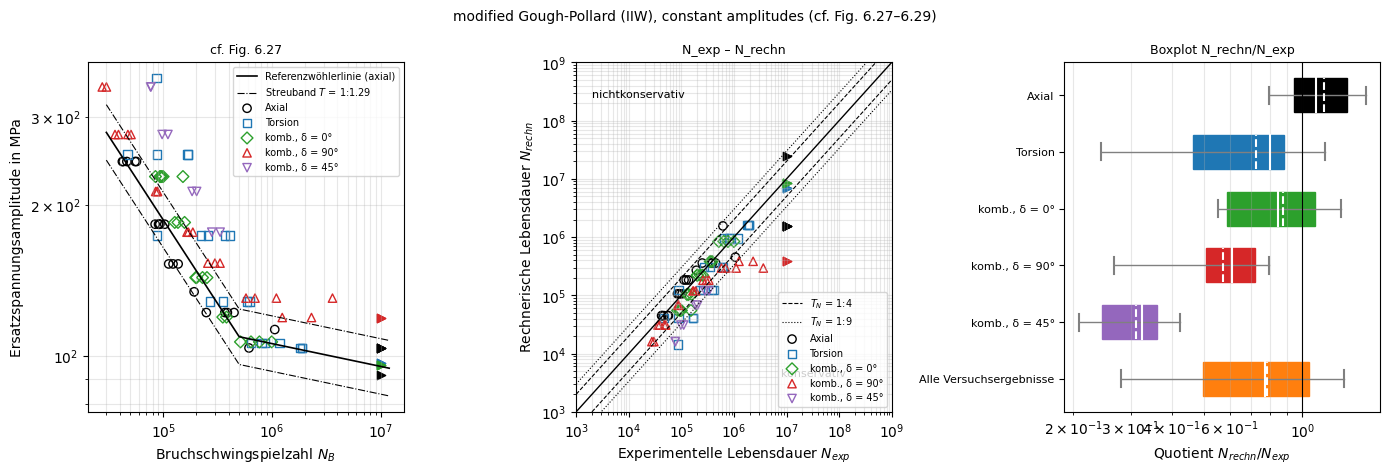

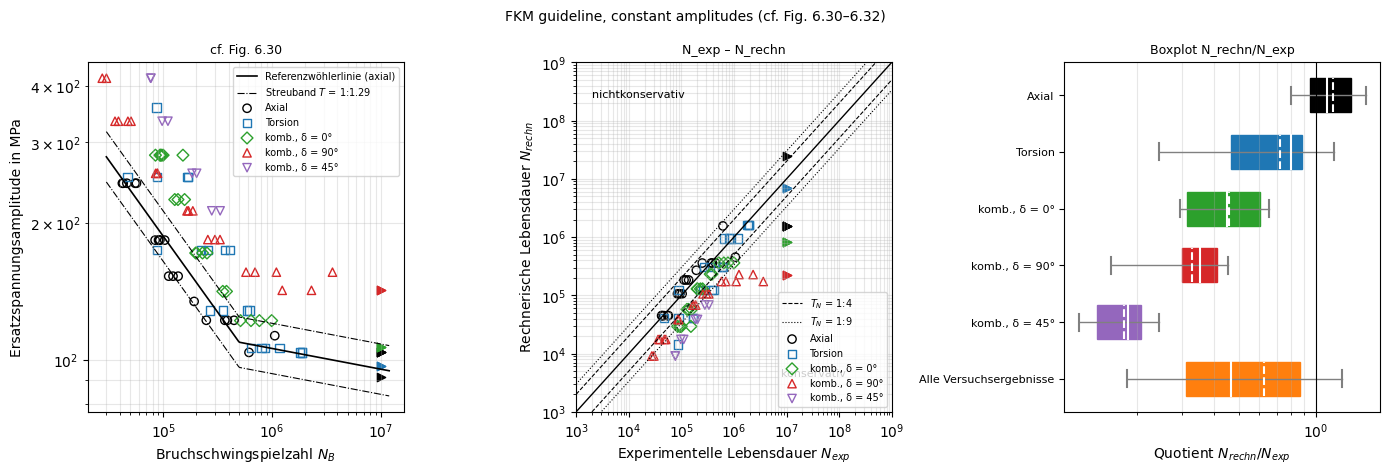

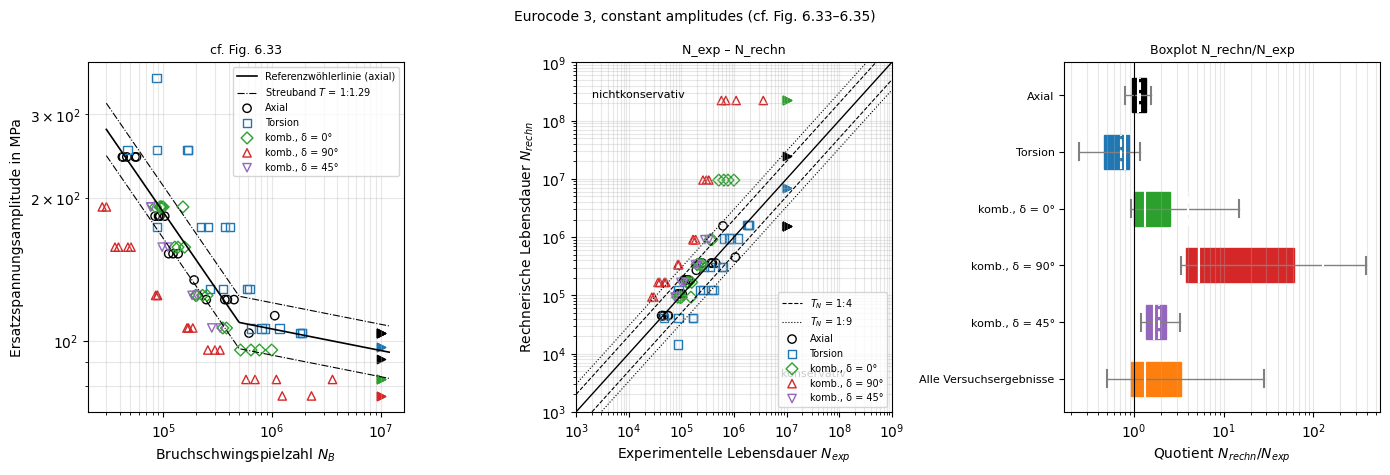

In [3]:
ca = df[df.amp == 'CA'].reset_index(drop=True)
mask_ca = include_in_statistics(ca, RUNOUT_POLICY)
sx, sy, tau = tf['c_x'] * ca.F_a.to_numpy(), tf['c_y'] * ca.F_a.to_numpy(), tf['c_xy'] * ca.M_ta.to_numpy()
prop = ~ca.loadcase.isin(['d90', 'd45']).to_numpy()
N_ca, stats_ca = {}, {}
for code, name, figs_ca, _ in CODES:
    N = np.array([life(code, a, b, c, ax_ca, tors_ca, pr) for a, b, c, pr in zip(sx, sy, tau, prop)])
    N_ca[code] = N
    fig = plt.figure(figsize=(14, 4.8))
    a1 = fig.add_subplot(1, 3, 1); a2 = fig.add_subplot(1, 3, 2); a3 = fig.add_subplot(1, 3, 3)
    plotting.sn_plot(a1, ca, ax_ca.L(N), ax_ca, T=P['scatter_band_reference_T'], ylabel='Ersatzspannungsamplitude in MPa',
                     title=f'cf. Fig. {figs_ca.split("–")[0]}')
    plotting.nn_plot(a2, ca, N, title='N_exp – N_rechn')
    stats_ca[code] = plotting.boxplot(a3, ca, N, mask_ca, title='Boxplot N_rechn/N_exp')
    fig.suptitle(f'{name}, constant amplitudes (cf. Fig. {figs_ca})', fontsize=10)
    plt.tight_layout(); plt.show()

In [4]:
def stats_table(stats):
    rows = []
    for code, st_c in stats.items():
        for g_, st in st_c.items():
            rows.append(dict(code=code, group=g_, n=st['n'], q10=st[0.1], q25=st[0.25], median=st[0.5],
                             q75=st[0.75], q90=st[0.9], mean=st['mean']))
    return pd.DataFrame(rows)

box_ca = stats_table(stats_ca)
display(box_ca.round(2))

,code,group,n,q10,q25,median,q75,q90,mean
0,IIW,ax,20,0.79,0.94,1.10,1.37,1.56,1.17
1,IIW,tors,21,0.24,0.46,0.80,0.88,1.17,0.72
2,IIW,d0,19,0.55,0.59,0.85,1.09,1.31,0.87
3,IIW,d90,21,0.27,0.51,0.61,0.72,0.79,0.57
4,IIW,d45,8,0.21,0.24,0.32,0.36,0.42,0.31
5,IIW,all,89,0.28,0.50,0.77,1.05,1.34,0.78
6,FKM,ax,20,0.79,0.94,1.10,1.37,1.56,1.17
7,FKM,tors,21,0.24,0.46,0.80,0.88,1.17,0.72
8,FKM,d0,19,0.29,0.31,0.45,0.60,0.65,0.46
9,FKM,d90,21,0.16,0.30,0.35,0.41,0.45,0.33


## Variable amplitudes – Figures 6.36–6.44
Standard rainflow count of the synthetic Gauss sequence (32 amplitude classes, seed 1). Every component has the same normalised cycles,
so the component amplitudes are $c_x \bar F_a x_c$, $c_y \bar F_a x_c$ and $c_{xy} \bar M_{t,a} x_c$.

cycles: 50440
pure axial: interaction equation with (2.25) == Palmgren-Miner (2.21): OK


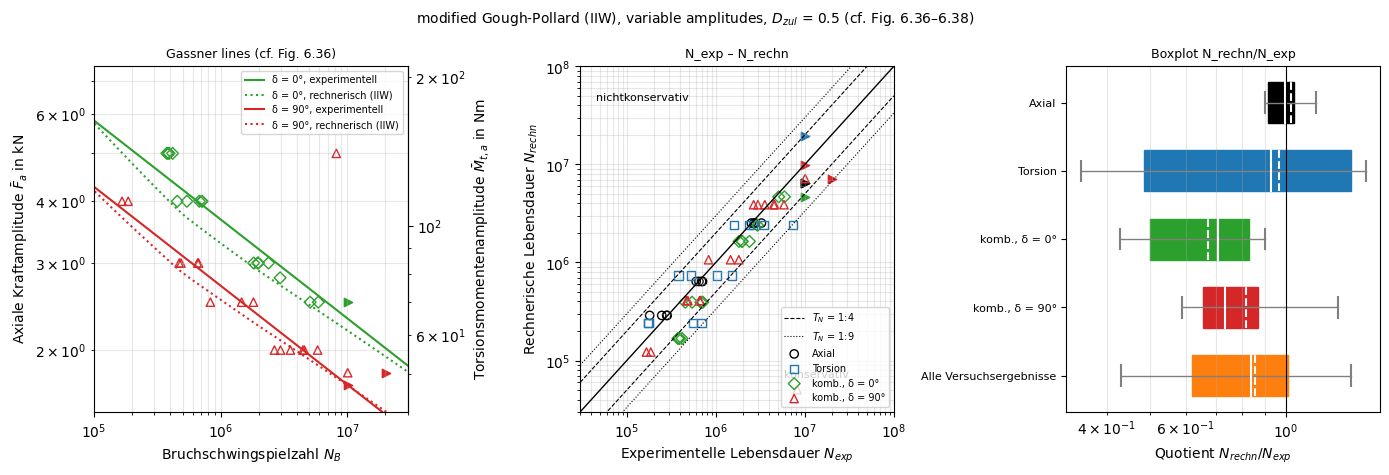

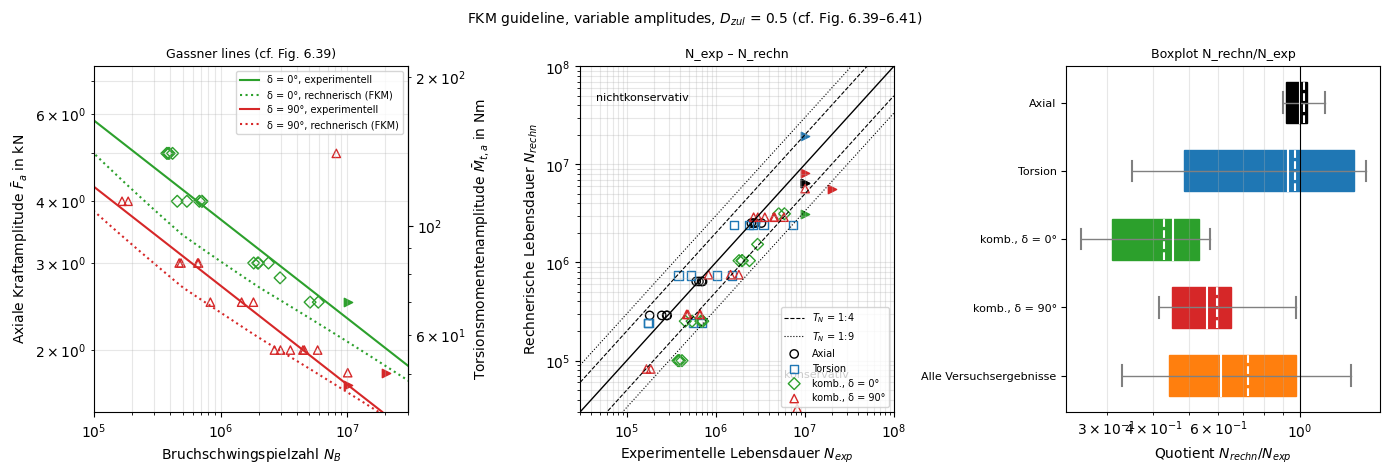

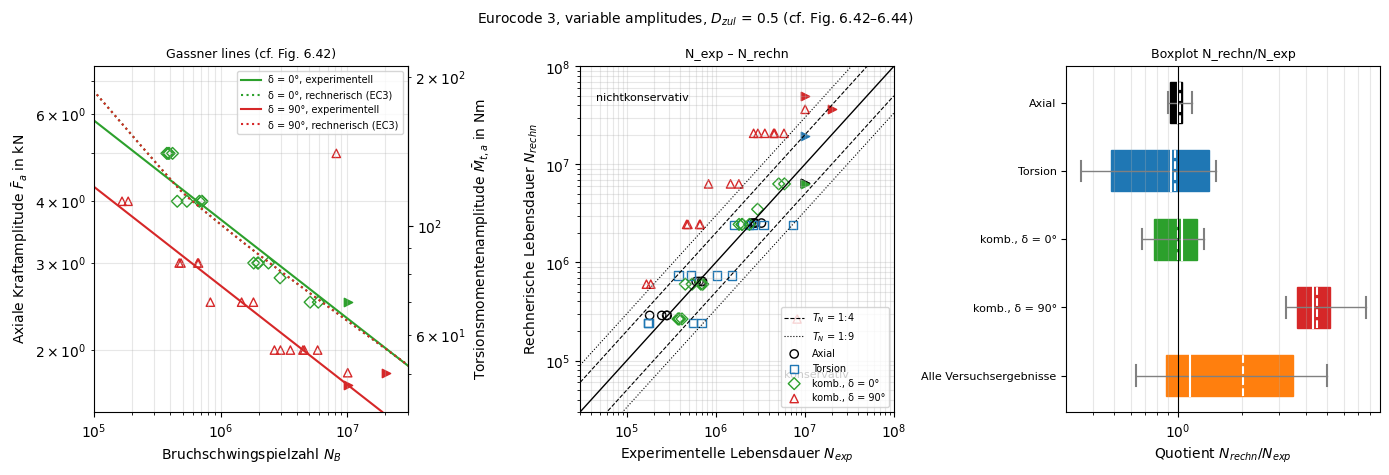

In [5]:
p_seq = gauss_reversals(P['L_TF'], seed=1, n_classes=32)
cyc, _ = rainflow_values(p_seq)
x_c = np.array([abs(a - b) / 2 for a, b in cyc])
print('cycles:', len(x_c))


def N_calc_VA(code, F, M, proportional):
    s_eq = L_eq(tf['c_x'] * F * x_c, 1.0, ax_va, P['D_zul']) if F > 0 else 0.0
    sy_eq = L_eq(tf['c_y'] * F * x_c, 1.0, ax_va, P['D_zul']) if F > 0 else 0.0
    t_eq = L_eq(tf['c_xy'] * M * x_c, 1.0, tors_va, P['D_zul']) if M > 0 else 0.0
    return life(code, s_eq, sy_eq, t_eq, ax_va, tors_va, proportional)


# consistency: for pure axial load the code approach equals Palmgren-Miner (2.21)
F_t = 4.5
D_TF = np.sum(1.0 / ax_va.N(tf['c_x'] * F_t * x_c))
assert abs(N_calc_VA('IIW', F_t, 0, True) / (len(x_c) / D_TF * P['D_zul']) - 1) < 1e-9
print('pure axial: interaction equation with (2.25) == Palmgren-Miner (2.21): OK')

va = df[df.amp == 'VA'].reset_index(drop=True)
mask_va = include_in_statistics(va, RUNOUT_POLICY)
g = P['gassner_normed_tab_3_11']
s_grid = np.logspace(np.log10(1.5), np.log10(7.5), 40)
N_va, stats_va = {}, {}
for code, name, _, figs_va in CODES:
    N = np.array([N_calc_VA(code, row.F_a, row.M_ta, row.loadcase != 'd90') for row in va.itertuples()])
    N_va[code] = N
    lines = {}
    for lc, col in (('d0', 'tab:green'), ('d90', 'tab:red')):
        lines[f'δ = {lc[1:]}°, experimentell'] = (g['N_A'] * (s_grid / g[lc]['L_A']) ** (-g[lc]['k']), s_grid, col, '-')
        lines[f'δ = {lc[1:]}°, rechnerisch ({code})'] = (np.array([N_calc_VA(code, s, r * s, lc == 'd0') for s in s_grid]), s_grid, col, ':')
    fig = plt.figure(figsize=(14, 4.8))
    a1 = fig.add_subplot(1, 3, 1); a2 = fig.add_subplot(1, 3, 2); a3 = fig.add_subplot(1, 3, 3)
    plotting.gassner_plot(a1, va, lines, r, title=f'Gassner lines (cf. Fig. {figs_va.split("–")[0]})')
    plotting.nn_plot(a2, va, N, lim=(3e4, 1e8), title='N_exp – N_rechn')
    stats_va[code] = plotting.boxplot(a3, va, N, mask_va, title='Boxplot N_rechn/N_exp')
    fig.suptitle(f'{name}, variable amplitudes, $D_{{zul}}$ = 0.5 (cf. Fig. {figs_va})', fontsize=10)
    plt.tight_layout(); plt.show()

In [6]:
box_va = stats_table(stats_va)
display(box_va.round(2))

,code,group,n,q10,q25,median,q75,q90,mean
0,IIW,ax,12,0.90,0.92,1.00,1.05,1.17,1.03
1,IIW,tors,13,0.35,0.48,0.93,1.40,1.51,0.97
2,IIW,d0,16,0.43,0.50,0.71,0.83,0.90,0.67
3,IIW,d90,17,0.59,0.66,0.73,0.87,1.31,0.82
4,IIW,all,58,0.43,0.62,0.84,1.01,1.40,0.85
5,FKM,ax,12,0.90,0.92,1.00,1.05,1.17,1.03
6,FKM,tors,13,0.35,0.48,0.93,1.40,1.51,0.97
7,FKM,d0,16,0.25,0.31,0.45,0.53,0.57,0.43
8,FKM,d90,17,0.41,0.45,0.56,0.65,0.97,0.59
9,FKM,all,58,0.33,0.44,0.61,0.97,1.37,0.72


## Sensitivity: FKM without the $\sigma_\parallel$ term
Section 6.3.4 states that IIW and FKM give very similar results. With $\sigma_\parallel = \sigma_y = 0.326\,\sigma_x$ and the axial curve as bearable amplitude,
the nonproportional FKM equation (2.38) becomes clearly more conservative than IIW.
Without the $\sigma_\parallel$ term, (2.38) for $a_\perp = a_\tau$ gives the same result as IIW with CV = 0.5.

In [7]:
N_fkm0 = np.array([life('FKM', a, 0.0, c, ax_ca, tors_ca, pr) for a, c, pr in zip(sx, tau, prop)])
ratio = lambda N: N / ca.N_B.to_numpy()
sens = pd.DataFrame({g_: {'IIW': np.median(ratio(N_ca['IIW'])[mask_ca & (ca.loadcase == g_).to_numpy()]),
                          'FKM (sigma_par = sigma_y)': np.median(ratio(N_ca['FKM'])[mask_ca & (ca.loadcase == g_).to_numpy()]),
                          'FKM (without sigma_par)': np.median(ratio(N_fkm0)[mask_ca & (ca.loadcase == g_).to_numpy()])}
                     for g_ in ('d0', 'd90', 'd45')}).T
display(sens.round(2))
print('-> question to the author: bearable amplitude for sigma_par in FKM (or sigma_par neglected)?')

,IIW,FKM (sigma_par = sigma_y),FKM (without sigma_par)
d0,0.85,0.45,0.55
d90,0.61,0.35,0.66
d45,0.32,0.18,0.34


-> question to the author: bearable amplitude for sigma_par in FKM (or sigma_par neglected)?


**EC3, δ = 90°:** Eq. (2.41) does not distinguish proportional and nonproportional loading, so δ = 0° and δ = 90° with the same amplitudes give the same $N_{rechn}$.
In Fig. 6.33 the δ = 90° points lie clearly higher (about 240 MPa at 3 kN) than the δ = 0° points (about 190 MPa), and here both give about 191 MPa.
The application in the dissertation therefore seems to contain an additional element for δ = 90° → **question to the author**.

## Comparison with the statements of Section 6.3.4

In [8]:
med = lambda tab, code, g_: float(tab[(tab.code == code) & (tab.group == g_)]['median'].iloc[0])
checks = [
    ('CA: IIW and FKM give very similar results',
     all(abs(np.log(med(box_ca, 'IIW', g_) / med(box_ca, 'FKM', g_))) < np.log(1.5) for g_ in ('ax', 'tors', 'd90', 'd45'))),
    ('CA: IIW/FKM assess all combined load cases conservatively',
     all(med(box_ca, c, g_) < 1.0 for c in ('IIW', 'FKM') for g_ in ('d0', 'd90', 'd45'))),
    ('CA: EC3 assesses all combined load cases non-conservatively (except 45°, Fig. 6.35)',
     all(med(box_ca, 'EC3', g_) > 1.0 for g_ in ('d0', 'd90'))),
    ('VA: all three codes conservative (Fig. 6.38, 6.41, 6.44)',
     all(med(box_va, c, 'all') < 1.0 for c in ('IIW', 'FKM', 'EC3'))),
    ('VA: EC3 more accurate than IIW/FKM (median closer to 1)',
     abs(np.log(med(box_va, 'EC3', 'all'))) < min(abs(np.log(med(box_va, 'IIW', 'all'))), abs(np.log(med(box_va, 'FKM', 'all'))))),
]
display(pd.DataFrame(checks, columns=['statement (Sec. 6.3.4)', 'reproduced']))

,statement (Sec. 6.3.4),reproduced
0,CA: IIW and FKM give very similar results,False
1,CA: IIW/FKM assess all combined load cases con...,True
2,CA: EC3 assesses all combined load cases non-c...,True
3,"VA: all three codes conservative (Fig. 6.38, 6...",False
4,VA: EC3 more accurate than IIW/FKM (median clo...,True


In [9]:
os.makedirs('results', exist_ok=True)
out_ca = ca[['table', 'specimen', 'loadcase', 'F_a', 'M_ta', 'delta', 'N_B', 'remark']].copy()
out_va = va[['table', 'specimen', 'loadcase', 'F_a', 'M_ta', 'delta', 'N_B', 'remark']].copy()
for code, *_ in CODES:
    out_ca[f'N_calc_{code}'] = N_ca[code]
    out_va[f'N_calc_{code}'] = N_va[code]
out_ca.to_csv('results/codes_constant_amplitudes.csv', index=False)
out_va.to_csv('results/codes_variable_amplitudes.csv', index=False)
print('written: results/codes_constant_amplitudes.csv, results/codes_variable_amplitudes.csv')

written: results/codes_constant_amplitudes.csv, results/codes_variable_amplitudes.csv
